# **Environmental forecast for the Monterrey Metropolitan Area**

## **Learning Gate**
#### **Tecnológico de Monterrey**
Performing an advanced statistical analysis using PCA to relate environmental variables to environmental pollution in order to create clasification models to predict environmental contingencies in the Monterrey Metropolitan Area.

**Name:**

*   René de la Calleja

**Creation Date:**

*   Oct/22/2026

In [1]:
from pyspark import SparkContext, SparkConf,SQLContext
from pyspark.sql import SparkSession
from pyspark.sql.functions import isnan, when, count, col, lit
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from numpy import sqrt,zeros,c_,amax,max

## Step 1: Exploring the dataset


In [2]:
# create sparksession and sparkcontext
sc = SparkContext.getOrCreate(SparkConf().setMaster("local[*]"))

spark = SparkSession \
    .builder \
    .getOrCreate()

In [3]:
sqlContext = SQLContext(sc)

/usr/local/lib/python3.13/dist-packages/pyspark/sql/context.py:112: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


In [7]:
path_csv="MonterreyPollutionData2.csv"
df = sqlContext.read.csv(path_csv,header=True,inferSchema=True)
df.show(10)

+---------+-----+---+-------+-------+----+----+----+----+----+---+----+-----+-----+-----+---+-----+----+---+---+
|     Date|Month|Day|DayWeek|WeekDay|Hour|  CO|  NO| NO2| NOX| O3|PM10|PM2.5|  PRS|RAINF| RH|   SR|TOUT|WSR|WDV|
+---------+-----+---+-------+-------+----+----+----+----+----+---+----+-----+-----+-----+---+-----+----+---+---+
|01-ene-15|    1|  1|    jue|      5|   1|2.51|10.2|12.9|23.1| 10| 139|   80|725.4| 0.01| 96|  0.0|3.91|7.2|344|
|01-ene-15|    1|  1|    jue|      5|   2|2.41| 9.2|11.6|20.8|  7|  42|   29|725.0| 0.02| 96|  0.0|3.81|6.3|341|
|01-ene-15|    1|  1|    jue|      5|   3|2.39| 8.1|11.8|19.9|  7|  23|    9|724.4|  0.0| 96|  0.0|3.85|5.2|346|
|01-ene-15|    1|  1|    jue|      5|   5|2.26| 5.3| 8.9|14.2|  7|  23|   14|724.0| 0.01| 96|  0.0|3.79|5.6|336|
|01-ene-15|    1|  1|    jue|      5|   8|2.25| 7.2|10.2|17.4|  5|  15|    8|724.3|  0.0| 96|0.023|3.93|4.8|354|
|01-ene-15|    1|  1|    jue|      5|   9|2.21| 5.8| 8.2|14.0|  7|  16|    6|724.3|  0.0| 96|0.0

In [8]:
df.printSchema()

root
 |-- Date: string (nullable = true)
 |-- Month: integer (nullable = true)
 |-- Day: integer (nullable = true)
 |-- DayWeek: string (nullable = true)
 |-- WeekDay: integer (nullable = true)
 |-- Hour: integer (nullable = true)
 |-- CO: double (nullable = true)
 |-- NO: double (nullable = true)
 |-- NO2: double (nullable = true)
 |-- NOX: double (nullable = true)
 |-- O3: integer (nullable = true)
 |-- PM10: integer (nullable = true)
 |-- PM2.5: integer (nullable = true)
 |-- PRS: double (nullable = true)
 |-- RAINF: double (nullable = true)
 |-- RH: integer (nullable = true)
 |-- SR: double (nullable = true)
 |-- TOUT: double (nullable = true)
 |-- WSR: double (nullable = true)
 |-- WDV: integer (nullable = true)



In [10]:
# Renaming column "PM2.5"
df = df.withColumnRenamed("PM2.5", "PM25")

df.describe().show()

+-------+----------+------------------+-----------------+-------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+-----------------+------------------+------------------+--------------------+-----------------+-------------------+-----------------+------------------+------------------+
|summary|      Date|             Month|              Day|DayWeek|           WeekDay|              Hour|                CO|                NO|               NO2|               NOX|                O3|             PM10|              PM25|               PRS|               RAINF|               RH|                 SR|             TOUT|               WSR|               WDV|
+-------+----------+------------------+-----------------+-------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+-----------------+------------------+------------------+------

In [11]:
from pyspark.sql import functions as F

# Q1: pollution profile by hour and by weekday
maxO3_PM25_by_date = (df.groupBy("Date")
                      .agg(F.max("O3").alias("O3"),
                            F.max("PM25").alias("PM2.5"))
                      .orderBy("Date").toPandas())

display(maxO3_PM25_by_date)


,Date,O3,PM2.5
0,01-abr-15,47,68
1,01-ene-15,14,80
2,01-feb-15,16,56
3,01-jul-15,28,40
4,01-mar-15,21,70
...,...,...,...
225,30/08/2015,49,57
226,31-ene-15,22,60
227,31-jul-15,50,32
228,31-mar-15,42,72


In [12]:
# 1. Climate variables (meteorological)
climate_cols = ["PRS", "RAINF", "RH", "SR", "TOUT", "WSR", "WDV"]

pollutant_cols = ["CO", "NO", "NO2", "NOX", "O3", "PM10", "PM25"]

# 2. Build min / avg / max aggregations for each variable
aggs = []
for c in climate_cols:
    aggs += [
        F.min(c).alias(f"{c}_min"),
        F.round(F.avg(c), 3).alias(f"{c}_avg"),
        F.max(c).alias(f"{c}_max"),
    ]

# 4. Group by day and store as a new dataframe
df_daily = (
    df.groupBy("Date", "Month", "Day")
      .agg(*aggs)
      .orderBy("Date")
)

df_daily.show(10, truncate=False)

+----------+-----+---+-------+-------+-------+---------+---------+-----------+------+------+------+------+------+-----------+--------+--------+--------+-------+-------+-------+-------+-------+-------+
|Date      |Month|Day|PRS_min|PRS_avg|PRS_max|RAINF_min|RAINF_avg|RAINF_max  |RH_min|RH_avg|RH_max|SR_min|SR_avg|SR_max     |TOUT_min|TOUT_avg|TOUT_max|WSR_min|WSR_avg|WSR_max|WDV_min|WDV_avg|WDV_max|
+----------+-----+---+-------+-------+-------+---------+---------+-----------+------+------+------+------+------+-----------+--------+--------+--------+-------+-------+-------+-------+-------+-------+
|01-abr-15 |4    |1  |715.7  |716.9  |718.1  |0.0      |0.0      |0.0        |67    |77.85 |94    |0.0   |0.173 |0.641      |18.92   |22.893  |26.04   |1.2    |8.03   |14.5   |21     |99.9   |352    |
|01-ene-15 |1    |1  |720.6  |722.459|725.4  |0.0      |0.002    |0.02       |93    |94.765|96    |0.0   |0.044 |0.175      |3.79    |5.554   |7.43    |2.9    |5.3    |8.2    |2      |145.706|354 

## Step 2. Starting PCA

Rows with unparseable Date: 0
+----+
|Date|
+----+
+----+

Days kept: 183 / 183  (dropped 0)
      eigenvalue  explained_var  cumulative
PC1        4.421          0.340       0.340
PC2        2.024          0.156       0.496
PC3        1.486          0.114       0.610
PC4        1.180          0.091       0.701
PC5        0.994          0.076       0.777
PC6        0.745          0.057       0.835
PC7        0.643          0.049       0.884
PC8        0.437          0.034       0.918
PC9        0.393          0.030       0.948
PC10       0.305          0.023       0.971
PC11       0.166          0.013       0.984
PC12       0.137          0.011       0.995
PC13       0.070          0.005       1.000
Row sums of cos² (should all be 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Components with eigenvalue > 1 (Kaiser): 4


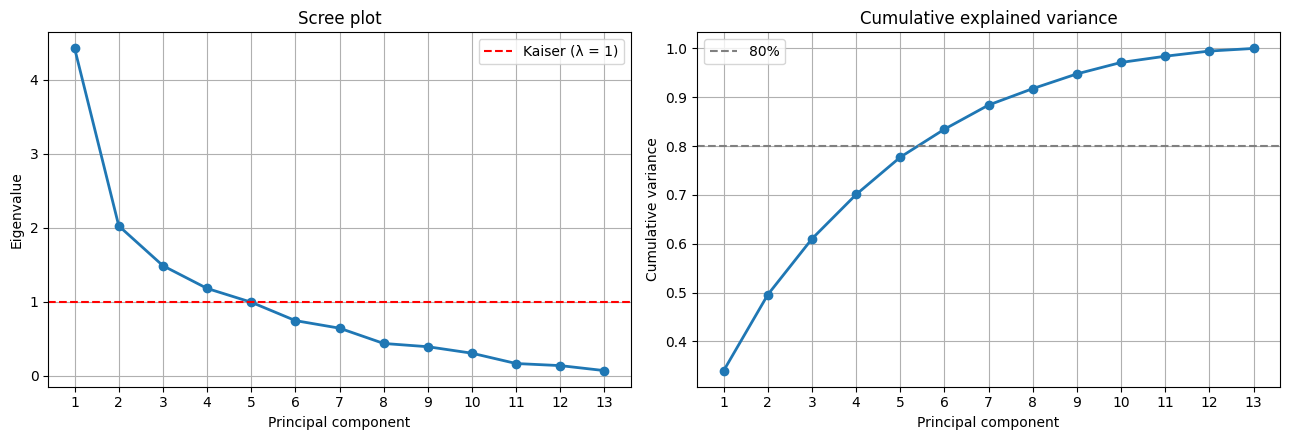

,PC1,PC2,PC3,PC4
Month_sin,0.403,0.001,0.176,0.014
Month_cos,0.501,0.162,0.012,0.076
IsWeekend,0.002,0.009,0.063,0.112
PRS_mean,0.362,0.000,0.217,0.100
RAINF_log,0.067,0.098,0.040,0.375
RH_mean,0.259,0.424,0.077,0.032
SR_max,0.735,0.063,0.002,0.000
TOUT_max,0.846,0.027,0.013,0.029
WSR_mean,0.460,0.178,0.106,0.001
WDV_sin,0.253,0.487,0.004,0.067


,PC1,PC2,PC3,PC4
Month_sin,9.1,0.1,11.8,1.2
Month_cos,11.3,8.0,0.8,6.4
IsWeekend,0.0,0.5,4.2,9.5
PRS_mean,8.2,0.0,14.6,8.5
RAINF_log,1.5,4.8,2.7,31.8
RH_mean,5.9,21.0,5.2,2.7
SR_max,16.6,3.1,0.2,0.0
TOUT_max,19.1,1.3,0.9,2.4
WSR_mean,10.4,8.8,7.1,0.1
WDV_sin,5.7,24.1,0.3,5.7


,PC1,PC2,PC3,PC4
Month_sin,-0.635,0.034,0.419,-0.118
Month_cos,-0.708,-0.402,-0.107,-0.275
IsWeekend,-0.041,-0.097,0.250,0.335
PRS_mean,-0.602,0.012,-0.466,-0.316
RAINF_log,-0.258,0.313,0.199,0.613
RH_mean,-0.509,0.651,0.278,0.179
SR_max,0.858,-0.250,-0.050,0.021
TOUT_max,0.920,-0.164,0.115,0.169
WSR_mean,0.678,0.422,-0.325,0.025
WDV_sin,0.503,0.698,0.063,-0.259


In [14]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA


month_map = {"ene":"01","feb":"02","mar":"03","abr":"04","may":"05","jun":"06",
             "jul":"07","ago":"08","sep":"09","oct":"10","nov":"11","dic":"12"}
mapping_expr = F.create_map([F.lit(x) for kv in month_map.items() for x in kv])

# Format A: 01-ene-15
pat_a = r"^\s*(\d{1,2})-([A-Za-z]{3})[A-Za-z]*-(\d{2,4})\s*$"
d = F.regexp_extract("Date", pat_a, 1)
m = mapping_expr[F.lower(F.regexp_extract("Date", pat_a, 2))]
y = F.regexp_extract("Date", pat_a, 3)
y = F.when(F.length(y) == 2, F.concat(F.lit("20"), y)).otherwise(y)

date_a = F.expr("CAST(try_to_timestamp(DateStrA, 'yyyy-MM-dd') AS DATE)")

# Format B: 05/08/2015  (dd/MM/yyyy)
date_b = F.expr("CAST(try_to_timestamp(Date, 'dd/MM/yyyy') AS DATE)")

df = (df
      .withColumn("DateStrA", F.concat_ws("-", y, m, F.lpad(d, 2, "0")))
      .withColumn("DateParsed", F.coalesce(date_a, date_b))
      .drop("DateStrA"))

# Diagnose: anything still failing?
bad = df.filter(F.col("DateParsed").isNull())
print("Rows with unparseable Date:", bad.count())
bad.select("Date").distinct().show(20, truncate=False)

df = df.filter(F.col("DateParsed").isNotNull())

# ------------------------------------------------------------------
# 1. Hourly-level prep: wind direction is circular, so convert to sin/cos
#    BEFORE aggregating (averaging raw degrees is wrong: mean(359, 1) != 0)
# ------------------------------------------------------------------
df = (df
      .withColumn("WDV_sin", F.sin(F.radians("WDV")))
      .withColumn("WDV_cos", F.cos(F.radians("WDV"))))

# ------------------------------------------------------------------
# 2. Daily aggregation
# ------------------------------------------------------------------
MIN_HOURS = 12   # discard days with too few valid O3 readings (a partial day gives a biased max)

daily = (df.groupBy("DateParsed")
    .agg(
        F.first("Month").alias("Month"),
        F.first("WeekDay").alias("WeekDay"),        # Spark convention: 1=Sunday ... 7=Saturday

        # Targets: daily maxima
        F.max("O3").alias("O3_max"),
        F.max("PM25").alias("PM25_max"),

        # Weather
        F.avg("PRS").alias("PRS_mean"),
        F.sum("RAINF").alias("RAINF_sum"),
        F.avg("RH").alias("RH_mean"),
        F.max("SR").alias("SR_max"),
        F.max("TOUT").alias("TOUT_max"),
        F.avg("WSR").alias("WSR_mean"),
        F.avg("WDV_sin").alias("WDV_sin"),          # circular mean components
        F.avg("WDV_cos").alias("WDV_cos"),

        F.count("O3").alias("n_hours"),
    )
    .filter(F.col("n_hours") >= MIN_HOURS)
)

# ------------------------------------------------------------------
# 3. Daily-level feature engineering
# ------------------------------------------------------------------
daily = (daily
    # Month -> cyclic (Dec is next to Jan)
    .withColumn("Month_sin", F.sin(2*math.pi*F.col("Month")/12))
    .withColumn("Month_cos", F.cos(2*math.pi*F.col("Month")/12))
    # WeekDay -> weekend flag (proxy for traffic/emission patterns)
    .withColumn("IsWeekend", F.when(F.col("WeekDay").isin(1, 7), 1.0).otherwise(0.0))
    # Skewed / zero-inflated variables -> log1p
    .withColumn("RAINF_log", F.log1p("RAINF_sum"))
    .withColumn("PM25_max_log", F.log1p("PM25_max"))
)

PCA_cols = [
    # time
    "Month_sin", "Month_cos", "IsWeekend",
    # weather
    "PRS_mean", "RAINF_log", "RH_mean", "SR_max", "TOUT_max",
    "WSR_mean", "WDV_sin", "WDV_cos",
    # pollutant maxima
    "O3_max", "PM25_max_log",
]
p = len(PCA_cols)   # 13

# ------------------------------------------------------------------
# 4. Drop nulls (and report what was lost)
# ------------------------------------------------------------------
n_before = daily.count()
PCA_df = daily.select("DateParsed", *PCA_cols).dropna()
n_after = PCA_df.count()
print(f"Days kept: {n_after} / {n_before}  (dropped {n_before - n_after})")

# ------------------------------------------------------------------
# 5. Assemble -> standardize -> PCA with k = p (full decomposition)
# ------------------------------------------------------------------
assembler = VectorAssembler(inputCols=PCA_cols, outputCol="features")
df_vector = assembler.transform(PCA_df).select("DateParsed", "features")

scaler = StandardScaler(inputCol="features", outputCol="scaledFeatures",
                        withMean=True, withStd=True)
scaledData = scaler.fit(df_vector).transform(df_vector)

pca = PCA(k=p, inputCol="scaledFeatures", outputCol="pcaFeatures")
model = pca.fit(scaledData)

# ------------------------------------------------------------------
# 6. Eigenvalues, loadings, cos², contributions
# ------------------------------------------------------------------
Q = model.pc.toArray()                             # eigenvectors, shape (p, p)
explained = model.explainedVariance.toArray()      # sums to 1 because k = p
eigvals = explained * p                            # correct factor: total variance = p
L = Q * np.sqrt(eigvals)                           # loadings = correlations variable–PC
COS2 = L**2                                        # quality of representation
CONTRIB = COS2 / eigvals * 100                     # % contribution of each variable to each PC

pc_names = [f"PC{i}" for i in range(1, p + 1)]
df_eig = pd.DataFrame({"eigenvalue": eigvals,
                       "explained_var": explained,
                       "cumulative": np.cumsum(explained)}, index=pc_names)
df_load = pd.DataFrame(L,       columns=pc_names, index=PCA_cols)
df_cos2 = pd.DataFrame(COS2,    columns=pc_names, index=PCA_cols)
df_ctr  = pd.DataFrame(CONTRIB, columns=pc_names, index=PCA_cols)

print(df_eig.round(3))
print("Row sums of cos² (should all be 1):", np.round(COS2.sum(axis=1), 6))
print("Components with eigenvalue > 1 (Kaiser):", int((eigvals > 1).sum()))

# ------------------------------------------------------------------
# 7. Scree + cumulative variance plots
# ------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
x = range(1, p + 1)

ax[0].plot(x, eigvals, "o-", lw=2)
ax[0].axhline(1, color="red", ls="--", label="Kaiser (λ = 1)")
ax[0].set(title="Scree plot", xlabel="Principal component", ylabel="Eigenvalue")
ax[0].set_xticks(list(x)); ax[0].legend(); ax[0].grid(True)

ax[1].plot(x, np.cumsum(explained), "o-", lw=2)
ax[1].axhline(0.80, color="gray", ls="--", label="80%")
ax[1].set(title="Cumulative explained variance", xlabel="Principal component",
          ylabel="Cumulative variance")
ax[1].set_xticks(list(x)); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.show()

# ------------------------------------------------------------------
# 8. Inspect results for the retained components
# ------------------------------------------------------------------
k_keep = int((eigvals > 1).sum())
keep = pc_names[:k_keep]

display(df_cos2[keep].round(3))    # how well each PC represents each variable
display(df_ctr[keep].round(1))     # which variables define each PC
display(df_load[keep].round(3))    # signed correlations (direction of the relationship)

# Sample scores (one row per day), if needed later
scores = model.transform(scaledData).select("DateParsed", "pcaFeatures")

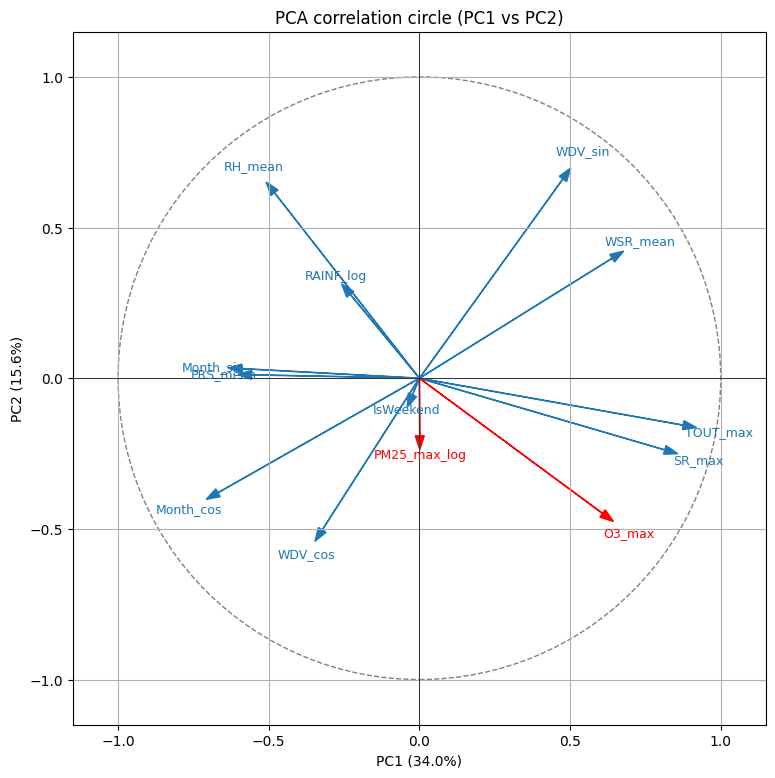

In [10]:
def correlation_circle(L, names, explained, pcx=0, pcy=1,
                       targets=("O3_max", "PM25_max_log")):
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.set_aspect("equal")
    ax.add_patch(plt.Circle((0, 0), 1, color="gray", fill=False, ls="--"))

    for i, name in enumerate(names):
        x, y = L[i, pcx], L[i, pcy]
        color = "red" if name in targets else "tab:blue"
        ax.arrow(0, 0, x, y, head_width=0.03, color=color,
                 length_includes_head=True)
        ax.text(x * 1.08, y * 1.08, name, color=color,
                ha="center", va="center", fontsize=9)

    ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15)
    ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
    ax.set_xlabel(f"PC{pcx+1} ({explained[pcx]*100:.1f}%)")
    ax.set_ylabel(f"PC{pcy+1} ({explained[pcy]*100:.1f}%)")
    ax.set_title(f"PCA correlation circle (PC{pcx+1} vs PC{pcy+1})")
    ax.grid(True)
    plt.show()

correlation_circle(L, PCA_cols, explained, 0, 1)

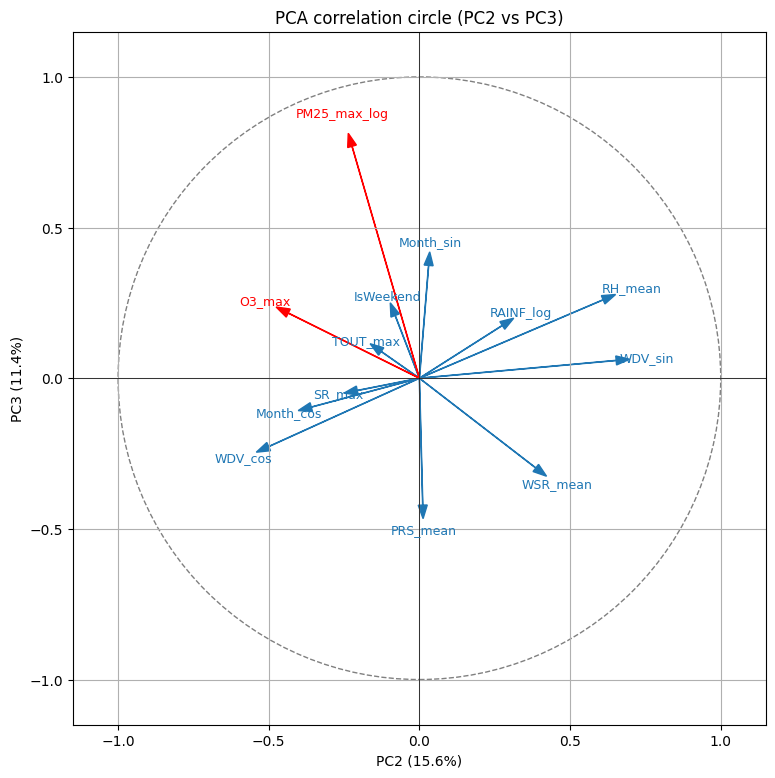

In [11]:
correlation_circle(L, PCA_cols, explained, 1, 2)

**Some first observations:**

O3_max has cos² of 0.42 on PC1 and 0.23 on PC2. In the PC1 vs PC2 circle it sits in the lower right, with the heat and sun arrows and opposite to RH_mean. Hot, sunny, dry days go with high O3. Across the four retained PCs, about 71% of its variance is represented, so the weather and time variables explain it reasonably well.

PM25_max_log is a different story. Its cos² is 0.00 on PC1 and 0.06 on PC2, so it is unrelated to the heat/sun axis. Almost all of it sits on PC3, a component that PM25 largely defines by itself (it contributes about 44% of PC3). When a component belongs to one variable, that variable mostly doesn’t co-vary with the others. In the PC2 vs PC3 circle:

It points opposite to PRS_mean and WSR_mean, so calmer, lower-pressure days go with higher PM2.5 peaks. Calm days fit physical accumulation.
It points the same way as Month_sin and, weakly, IsWeekend.
These are hypotheses from a 2D projection, so the Spearman table needs to confirm them.

**Conclusions so far:**

*   O3 contingencies should be reasonably predictable from temperature, radiation and humidity.
*   PM25 contingencies will be harder with only time and weather variables, the previous day’s PM25 will likely help more than any weather variable.
*   Redundant pairs: TOUT_max with SR_max, and Month_sin with PRS_mean (their arrows overlap in the PC1 vs PC2 plot).
* IsWeekend is weak, with cos² under 0.12 on all four retained PCs. It is a candidate to drop.









In [15]:
# Analyzing how many months we have in our grouped data
daily.groupBy("Month").count().orderBy("Month").show()

+-----+-----+
|Month|count|
+-----+-----+
|    1|   25|
|    2|   22|
|    3|   24|
|    4|   28|
|    5|   16|
|    6|    6|
|    7|   22|
|    8|   25|
|    9|    1|
|   10|   11|
|   11|    3|
+-----+-----+



In [13]:
# This is a study to see how many days we keep from the original dataset after the filter above, in order to check if our study is still valid.
import pandas as pd

dates = pd.to_datetime(PCA_df.select("DateParsed").toPandas()["DateParsed"]).sort_values().reset_index(drop=True)
gaps = dates.diff().dt.days

print("Years:", dates.dt.year.value_counts().sort_index().to_dict())
print("Date range:", dates.min().date(), "->", dates.max().date())
print("Consecutive-day pairs:", int((gaps == 1).sum()), "of", len(dates) - 1)

run_id = (gaps != 1).cumsum()
print("Longest run of consecutive days:", run_id.value_counts().max())

print("Distinct days in raw data:", df.select("DateParsed").distinct().count(), "| kept:", len(dates))

Years: {2015: 183}
Date range: 2015-01-01 -> 2015-11-06
Consecutive-day pairs: 149 of 182
Longest run of consecutive days: 25
Distinct days in raw data: 230 | kept: 183


Predictors vs targets, same day (* = p < 0.05)


,rho_O3_max,sig_O3_max,rho_PM25_max_log,sig_PM25_max_log,max_abs_rho
variable,,,,,
RH_mean,-0.61,*,0.04,,0.61
TOUT_max,0.59,*,-0.00,,0.59
SR_max,0.52,*,-0.12,,0.52
PRS_mean,-0.44,*,-0.23,*,0.44
RAINF_log,-0.39,*,-0.04,,0.39
WSR_mean,0.12,,-0.29,*,0.29
Month_sin,-0.19,*,0.26,*,0.26
Month_cos,-0.20,*,0.18,*,0.20
IsWeekend,-0.03,,0.13,,0.13


Consecutive-day pairs available: 149
Predictors today vs targets tomorrow (* = p < 0.05)


,rho_O3_max_next,sig_O3_max_next,rho_PM25_max_log_next,sig_PM25_max_log_next,max_abs_rho
variable,,,,,
RH_mean,-0.46,*,0.14,,0.46
TOUT_max,0.39,*,-0.09,,0.39
SR_max,0.38,*,-0.19,*,0.38
RAINF_log,-0.34,*,-0.09,,0.34
WSR_mean,0.05,,-0.29,*,0.29
PRS_mean,-0.26,*,-0.13,,0.26
Month_cos,-0.14,,0.25,*,0.25
Month_sin,-0.13,,0.23,*,0.23
WDV_cos,-0.00,,-0.12,,0.12


Highly correlated predictor pairs (|rho| >= 0.8)


,var1,var2,rho
45,SR_max,TOUT_max,0.835752


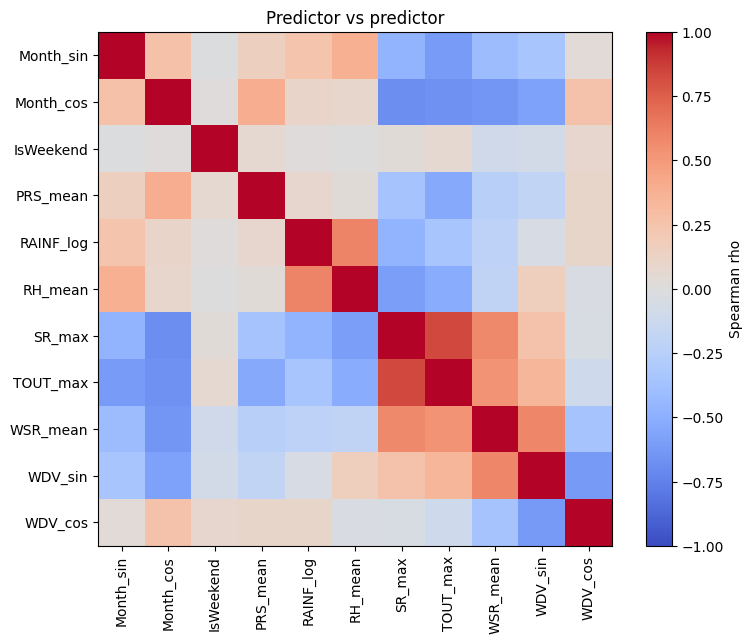

Threshold |rho| >= 0.15
Keep : ['Month_sin', 'Month_cos', 'PRS_mean', 'RAINF_log', 'RH_mean', 'SR_max', 'TOUT_max', 'WSR_mean']
Drop candidates: ['IsWeekend', 'WDV_sin', 'WDV_cos']


In [14]:
# Here we analyze correlation between Predictors and targets through spearman index.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

targets    = ["O3_max", "PM25_max_log"]
predictors = [c for c in PCA_cols if c not in targets]

pdf = PCA_df.toPandas()
pdf["date"] = pd.to_datetime(pdf["DateParsed"])
pdf = pdf.sort_values("date").reset_index(drop=True)
n = len(pdf)

def spearman_table(data, predictors, targets):
    rows = []
    for p in predictors:
        row = {"variable": p}
        for t in targets:
            rho, pval = spearmanr(data[p], data[t], nan_policy="omit")
            row[f"rho_{t}"], row[f"p_{t}"] = rho, pval
        rows.append(row)
    return pd.DataFrame(rows).set_index("variable")

def summarize(tbl, targets):
    out = pd.DataFrame(index=tbl.index)
    for t in targets:
        out[f"rho_{t}"] = tbl[f"rho_{t}"].round(2)
        out[f"sig_{t}"] = np.where(tbl[f"p_{t}"] < 0.05, "*", "")
    out["max_abs_rho"] = tbl[[f"rho_{t}" for t in targets]].abs().max(axis=1).round(2)
    return out.sort_values("max_abs_rho", ascending=False)

# 1) Same-day relationship
tbl_same = spearman_table(pdf, predictors, targets)
print("Predictors vs targets, same day (* = p < 0.05)")
display(summarize(tbl_same, targets))

# 2) Next-day relationship (what a forecast actually needs)
consecutive = (pdf["date"].shift(-1) - pdf["date"]).dt.days == 1
for t in targets:
    pdf[f"{t}_next"] = pdf[t].shift(-1).where(consecutive)
targets_next = [f"{t}_next" for t in targets]
print("Consecutive-day pairs available:", int(consecutive.sum()))
tbl_next = spearman_table(pdf, predictors, targets_next)
print("Predictors today vs targets tomorrow (* = p < 0.05)")
display(summarize(tbl_next, targets_next))

# 3) Redundancy among predictors
corr_pred = pdf[predictors].corr(method="spearman")
pairs = (corr_pred.where(np.triu(np.ones(corr_pred.shape, dtype=bool), k=1))
         .stack().reset_index())
pairs.columns = ["var1", "var2", "rho"]
print("Highly correlated predictor pairs (|rho| >= 0.8)")
display(pairs[pairs["rho"].abs() >= 0.8].sort_values("rho", key=abs, ascending=False))

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr_pred, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(predictors))); ax.set_xticklabels(predictors, rotation=90)
ax.set_yticks(range(len(predictors))); ax.set_yticklabels(predictors)
plt.colorbar(im, label="Spearman rho"); plt.title("Predictor vs predictor"); plt.tight_layout(); plt.show()

# 4) Automatic drop candidates (sin/cos pairs are judged together)
groups = {"Month": ["Month_sin", "Month_cos"], "WDV": ["WDV_sin", "WDV_cos"]}
group_of = {v: g for g, vs in groups.items() for v in vs}
unit = pd.Series({v: group_of.get(v, v) for v in predictors})

THRESH = 1.96 / np.sqrt(n - 1)     # ~0.19 for n = 108 (approx. |rho| needed for p < 0.05)
rho_cols = [f"rho_{t}" for t in targets]
strength = tbl_same[rho_cols].abs().max(axis=1).groupby(unit).max()

keep = [v for v in predictors if strength[unit[v]] >= THRESH]
drop = [v for v in predictors if v not in keep]
print(f"Threshold |rho| >= {THRESH:.2f}")
print("Keep :", keep)
print("Drop candidates:", drop)

**What the tables say**

*   O3_max is clearly predictable from weather. The same-day rho values are RH_mean −0.61, TOUT_max +0.59, SR_max +0.52, PRS_mean −0.44 and RAINF_log −0.39. They drop for next-day (−0.46, +0.39, +0.38, −0.26, −0.34) but keep the same ranking and signs. That drop is expected, since today’s weather only partly predicts tomorrow’s.
* PM25_max_log is weak. The strongest value is WSR_mean at −0.29 (calm days go with higher peaks), followed by Month_sin/Month_cos at about +0.2 to +0.26, and PRS_mean at −0.23 same-day only. Since rho² ≈ 0.08, weather and time explain roughly 8% of the rank variance at best.







In [18]:
# Now, let's analyze the target data distribution:

from pyspark.sql import Window, functions as F

final_features = ["TOUT_max", "SR_max", "RH_mean", "PRS_mean",
                  "RAINF_log", "WSR_mean", "Month_sin", "Month_cos"]

w = Window.orderBy("DateParsed")
model_df = (daily
    .select("DateParsed", *final_features, "O3_max", "PM25_max")
    .withColumn("next_date",     F.lead("DateParsed").over(w))
    .withColumn("O3_max_next",   F.lead("O3_max").over(w))
    .withColumn("PM25_max_next", F.lead("PM25_max").over(w))
    .filter(F.datediff("next_date", "DateParsed") == 1)   # strictly consecutive days only
    .drop("next_date")
    .dropna())

print("Modeling rows:", model_df.count())
model_df.select(
    F.expr("percentile_approx(O3_max_next,   array(0.5, 0.75, 0.9, 0.95))").alias("O3_pcts"),
    F.expr("percentile_approx(PM25_max_next, array(0.5, 0.75, 0.9, 0.95))").alias("PM25_pcts"),
    F.max("O3_max_next").alias("O3_peak"),
    F.max("PM25_max_next").alias("PM25_peak"),
).show(truncate=False)

Modeling rows: 149
+----------------+-----------------+-------+---------+
|O3_pcts         |PM25_pcts        |O3_peak|PM25_peak|
+----------------+-----------------+-------+---------+
|[49, 63, 74, 81]|[54, 70, 90, 105]|89     |123      |
+----------------+-----------------+-------+---------+



In [19]:
# Now let's review the class counts taking into account the following thresholds, we'll predict for three classes:
# "good", "regular" and "contingency"

from pyspark.sql import functions as F

# Thresholds (edit here if needed)
O3_GOOD_MAX, O3_REG_MAX = 55, 111
PM_GOOD_MAX, PM_REG_MAX = 15.4, 40.4

def add_class(df, value_col, good_max, reg_max, prefix):
    v = F.col(value_col)
    return (df
        .withColumn(f"{prefix}_class_next",
            F.when(v <= good_max, "good")
             .when(v <= reg_max, "regular")
             .otherwise("contingency"))
        .withColumn(f"{prefix}_label_next",          # numeric label for MLlib
            F.when(v <= good_max, 0.0)
             .when(v <= reg_max, 1.0)
             .otherwise(2.0)))

model_df = add_class(model_df, "O3_max_next",   O3_GOOD_MAX, O3_REG_MAX, "O3")
model_df = add_class(model_df, "PM25_max_next", PM_GOOD_MAX, PM_REG_MAX, "PM25")

# Class distribution
total = model_df.count()
for p in ["O3", "PM25"]:
    print(f"--- {p} (next day) ---")
    (model_df.groupBy(f"{p}_class_next", f"{p}_label_next")
        .agg(F.count("*").alias("days"),
             F.round(F.count("*") / total * 100, 1).alias("pct"))
        .orderBy(f"{p}_label_next")
        .show())

--- O3 (next day) ---
+-------------+-------------+----+----+
|O3_class_next|O3_label_next|days| pct|
+-------------+-------------+----+----+
|         good|          0.0|  93|62.4|
|      regular|          1.0|  56|37.6|
+-------------+-------------+----+----+

--- PM25 (next day) ---
+---------------+---------------+----+----+
|PM25_class_next|PM25_label_next|days| pct|
+---------------+---------------+----+----+
|        regular|            1.0|  30|20.1|
|    contingency|            2.0| 119|79.9|
+---------------+---------------+----+----+



In [17]:
# PM25 has only two classes, and they are labeled 1.0 and 2.0. Spark MLlib classifiers expect labels starting at 0,
# so training on 1.0/2.0 would raise an error or behave wrongly.
# The code adds a binary label, PM25_label_bin, where 0 = regular and 1 = contingency.

from pyspark.sql import Window, functions as F

TRAIN_FRAC = 0.8

# 1) Order by date and add a binary PM25 label (0 = regular, 1 = contingency)
w = Window.orderBy("DateParsed")
ordered = (model_df
    .withColumn("row_id", F.row_number().over(w))
    .withColumn("PM25_label_bin",
                F.when(F.col("PM25_class_next") == "contingency", 1.0).otherwise(0.0))
    .cache())

# 2) Chronological split: first 80% of dates = train, last 20% = test
n = ordered.count()
n_train = int(n * TRAIN_FRAC)

train_df = ordered.filter(F.col("row_id") <= n_train).cache()
test_df  = ordered.filter(F.col("row_id") >  n_train).cache()

# 3) Sanity checks
print(f"Total: {n} | train: {train_df.count()} | test: {test_df.count()}")

for name, d in [("TRAIN", train_df), ("TEST", test_df)]:
    r = d.agg(F.min("DateParsed").alias("from"), F.max("DateParsed").alias("to")).first()
    print(f"{name}: {r['from']} -> {r['to']}")

print("\nPM25 class balance")
for name, d in [("train", train_df), ("test", test_df)]:
    print(name)
    d.groupBy("PM25_class_next").count().orderBy("PM25_class_next").show()

print("O3_max_next (regression target) summary")
for name, d in [("train", train_df), ("test", test_df)]:
    print(name)
    d.select("O3_max_next").summary("min", "50%", "max").show()

print("Test days by month")
test_df.groupBy(F.month("DateParsed").alias("month")).count().orderBy("month").show()

Total: 149 | train: 119 | test: 30
TRAIN: 2015-01-01 -> 2015-07-28
TEST: 2015-07-29 -> 2015-11-05

PM25 class balance
train
+---------------+-----+
|PM25_class_next|count|
+---------------+-----+
|    contingency|   96|
|        regular|   23|
+---------------+-----+

test
+---------------+-----+
|PM25_class_next|count|
+---------------+-----+
|    contingency|   23|
|        regular|    7|
+---------------+-----+

O3_max_next (regression target) summary
train
+-------+-----------+
|summary|O3_max_next|
+-------+-----------+
|    min|         10|
|    50%|         45|
|    max|         89|
+-------+-----------+

test
+-------+-----------+
|summary|O3_max_next|
+-------+-----------+
|    min|         33|
|    50%|         61|
|    max|         89|
+-------+-----------+

Test days by month
+-----+-----+
|month|count|
+-----+-----+
|    7|    3|
|    8|   22|
|   10|    3|
|   11|    2|
+-----+-----+



Some observations from the Train-Test sets split:



*   The test set is mostly one month. 22 of the 30 test days are in August, plus 3 in July, 3 in October and 2 in November, so the test scores mainly measure “how well do we predict August from January to July”.
*   There is a distribution shift in O3. The train median is 45 (mostly “good”), while the test median is 61 (mostly “regular”). A model that learned the Jan-Jul pattern may underpredict in August, so the code reports bias (mean error) as well as RMSE and MAE.
*  PM25 test has only 7 “regular” days. Always predicting “contingency” scores 23/30 = 77%, so accuracy alone says nothing. The code reports recall for each class and AUC.



In [18]:
import numpy as np
import pandas as pd
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import RegressionEvaluator, BinaryClassificationEvaluator
from pyspark.sql import functions as F

feature_sets = {
    "with_month": final_features,
    "no_month":   [c for c in final_features if not c.startswith("Month_")],
}

def prep_stages(cols):
    # The scaler is part of the Pipeline, so fit() on train learns the mean/std from train only
    return [VectorAssembler(inputCols=cols, outputCol="raw_features"),
            StandardScaler(inputCol="raw_features", outputCol="features",
                           withMean=True, withStd=True)]

# ------------------------------------------------------------------
# A) O3: regression, then apply the thresholds to the prediction
# ------------------------------------------------------------------
def o3_class(c):
    c = F.round(c)
    return (F.when(c <= O3_GOOD_MAX, "good")
             .when(c <= O3_REG_MAX, "regular")
             .otherwise("contingency"))

def eval_o3(pred, label="O3_max_next"):
    ev = lambda m: RegressionEvaluator(labelCol=label, predictionCol="prediction",
                                       metricName=m).evaluate(pred)
    p = pred.withColumn("pred_class", o3_class(F.col("prediction")))
    n = p.count()
    acc = p.filter(F.col("pred_class") == F.col("O3_class_next")).count() / n
    def recall(cls):
        d = p.filter(F.col("O3_class_next") == cls)
        k = d.count()
        return d.filter(F.col("pred_class") == cls).count() / k if k else np.nan
    bias = pred.agg(F.avg(F.col("prediction") - F.col(label))).first()[0]
    return {"RMSE": ev("rmse"), "MAE": ev("mae"), "R2": ev("r2"), "bias": bias,
            "class_acc": acc, "recall_good": recall("good"), "recall_regular": recall("regular")}

def lr(reg, en):
    return LinearRegression(featuresCol="features", labelCol="O3_max_next",
                            regParam=reg, elasticNetParam=en)
def rf(depth):
    return RandomForestRegressor(featuresCol="features", labelCol="O3_max_next",
                                 numTrees=200, maxDepth=depth,
                                 minInstancesPerNode=5, seed=42)

grids = {
    "LinearReg":  [(f"reg={r},en={e}", (lambda r=r, e=e: lr(r, e)))
                   for r in [0.01, 0.1, 1.0] for e in [0.0, 0.5, 1.0]],
    "RandForest": [(f"depth={d}", (lambda d=d: rf(d))) for d in [2, 3, 5]],
}

rmse_ev = RegressionEvaluator(labelCol="O3_max_next", predictionCol="prediction",
                              metricName="rmse")

def expanding_cv(make_model, cols, data, n_folds=4, min_train_frac=0.5):
    """Train on the earliest block, validate on the block right after it, then expand."""
    n = data.count()
    start = int(n * min_train_frac)
    step = (n - start) // n_folds
    scores = []
    for k in range(n_folds):
        tr_end = start + k * step
        va_end = tr_end + step
        tr = data.filter(F.col("row_id") <= tr_end)
        va = data.filter((F.col("row_id") > tr_end) & (F.col("row_id") <= va_end))
        m = Pipeline(stages=prep_stages(cols) + [make_model()]).fit(tr)
        scores.append(rmse_ev.evaluate(m.transform(va)))
    return float(np.mean(scores))

rows = []

# Baseline: constant = median of the training O3 (time/weather-only requirement)
med = float(train_df.approxQuantile("O3_max_next", [0.5], 0.01)[0])
base = test_df.withColumn("prediction", F.lit(med))
rows.append({"features": "-", "model": "Baseline (train median)", "params": f"{med}",
             "cv_rmse": np.nan, **eval_o3(base)})

for fs_name, cols in feature_sets.items():
    for fam, options in grids.items():
        scored = [(expanding_cv(mk, cols, train_df), pname, mk) for pname, mk in options]
        cv_rmse, best_name, best_mk = min(scored, key=lambda t: t[0])
        final = Pipeline(stages=prep_stages(cols) + [best_mk()]).fit(train_df)
        rows.append({"features": fs_name, "model": fam, "params": best_name,
                     "cv_rmse": cv_rmse, **eval_o3(final.transform(test_df))})

res_o3 = pd.DataFrame(rows).round(3)
display(res_o3)

# ------------------------------------------------------------------
# B) PM25: binary classification (1 = contingency, 0 = regular)
# ------------------------------------------------------------------
n_tr = train_df.count()
n_pos = train_df.filter(F.col("PM25_label_bin") == 1).count()
n_neg = n_tr - n_pos
w_pos, w_neg = n_tr / (2 * n_pos), n_tr / (2 * n_neg)     # balanced class weights
train_w = train_df.withColumn(
    "w", F.when(F.col("PM25_label_bin") == 1, w_pos).otherwise(w_neg))

def eval_pm25(pred):
    L, P = F.col("PM25_label_bin"), F.col("prediction")
    tp = pred.filter((L == 1) & (P == 1)).count()
    fn = pred.filter((L == 1) & (P == 0)).count()
    tn = pred.filter((L == 0) & (P == 0)).count()
    fp = pred.filter((L == 0) & (P == 1)).count()
    rec_c = tp / (tp + fn) if tp + fn else np.nan     # contingency days caught
    rec_r = tn / (tn + fp) if tn + fp else np.nan     # regular days correctly recognized
    auc = (BinaryClassificationEvaluator(labelCol="PM25_label_bin",
           rawPredictionCol="rawPrediction", metricName="areaUnderROC").evaluate(pred)
           if "rawPrediction" in pred.columns else np.nan)
    return {"accuracy": (tp + tn) / (tp + tn + fp + fn), "recall_contingency": rec_c,
            "recall_regular": rec_r, "balanced_acc": np.nanmean([rec_c, rec_r]),
            "AUC": auc, "TP": tp, "FN": fn, "TN": tn, "FP": fp}

rows = []
base = test_df.withColumn("prediction", F.lit(1.0))          # always "contingency"
rows.append({"features": "-", "model": "Baseline (always contingency)", **eval_pm25(base)})

clfs = {
    "LogReg":     lambda: LogisticRegression(featuresCol="features", labelCol="PM25_label_bin",
                                             weightCol="w", regParam=0.1, elasticNetParam=0.0),
    "RandForest": lambda: RandomForestClassifier(featuresCol="features", labelCol="PM25_label_bin",
                                                 weightCol="w", numTrees=200, maxDepth=3,
                                                 minInstancesPerNode=5, seed=42),
}
for fs_name, cols in feature_sets.items():
    for cname, mk in clfs.items():
        m = Pipeline(stages=prep_stages(cols) + [mk()]).fit(train_w)
        rows.append({"features": fs_name, "model": cname, **eval_pm25(m.transform(test_df))})

res_pm = pd.DataFrame(rows).round(3)
display(res_pm)

,features,model,params,cv_rmse,RMSE,MAE,R2,bias,class_acc,recall_good,recall_regular
0,-,Baseline (train median),45.0,NaN,20.285,16.633,-1.319,-15.300,0.400,1.000,0.000
1,with_month,LinearReg,"reg=1.0,en=1.0",17.050,18.159,14.071,-0.859,-12.976,0.400,1.000,0.000
2,with_month,RandForest,depth=2,16.087,14.750,10.900,-0.226,-8.771,0.400,1.000,0.000
3,no_month,LinearReg,"reg=1.0,en=0.5",17.135,12.267,8.846,0.152,-3.577,0.800,0.667,0.889
4,no_month,RandForest,depth=2,16.366,14.456,10.617,-0.178,-8.050,0.467,1.000,0.111


,features,model,accuracy,recall_contingency,recall_regular,balanced_acc,AUC,TP,FN,TN,FP
0,-,Baseline (always contingency),0.767,1.000,0.000,0.500,NaN,23,0,0,7
1,with_month,LogReg,0.233,0.043,0.857,0.450,0.429,1,22,6,1
2,with_month,RandForest,0.600,0.696,0.286,0.491,0.609,16,7,2,5
3,no_month,LogReg,0.567,0.696,0.143,0.419,0.528,16,7,1,6
4,no_month,RandForest,0.600,0.739,0.143,0.441,0.559,17,6,1,6


### Some first observations from the results:

**O3 (regression, then thresholds)**

*   Only no_month + LinearReg clearly beats the baseline. RMSE drops from 20.3 to 12.3, class accuracy rises from 0.40 to 0.80, and R² is slightly positive (0.15). It catches 16 of 18 regular days and 8 of 12 good days, and its bias is only −3.6.
*  The month features hurt. with_month + LinearReg has R² of −0.86 and recall_regular of 0, so it behaves like the baseline. The model trained on Jan-Jul has never seen the month encodings of August.
*  Both random forests underpredict (bias −8 to −9) and call almost every day “good”. Trees can’t predict above what they saw in training, and the test period is warmer and has more ozone.
*  Two best hyperparameters sit at the edge of the grid (reg=1.0 is the largest value tried, and depth=2 the smallest). Widening the grid, for example reg in [1, 3, 10] and depth in [1, 2], is worth doing.


**PM25 (contingency vs regular)**

No model beats chance.

*  Every balanced accuracy is ≤ 0.49, and every model’s accuracy (0.23 to 0.60) is below the 0.767 of “always contingency”.
*  AUC ranges from 0.43 to 0.61. With only 7 regular days, the standard error of an AUC is about 0.13, so all of these are indistinguishable from 0.5.
*  with_month LogReg is the extreme case: it labels almost everything “regular” (22 contingency days missed).
*  This matches the weak Spearman results (|rho| ≤ 0.29). It seems that time and weather variables alone don’t predict PM25 contingencies on this data.


In [19]:
#  Including also XGBoost algorithm.

from pyspark.ml.regression import GBTRegressor
from pyspark.ml.classification import GBTClassifier

try:
    from xgboost.spark import SparkXGBRegressor, SparkXGBClassifier
    HAS_XGB = True
except Exception as e:
    HAS_XGB = False
    print("xgboost.spark not available, running GBT only:", repr(e)[:200])

# Reuses from earlier cells: feature_sets, prep_stages, expanding_cv, eval_o3, eval_pm25,
# train_df, test_df, train_w, res_o3, res_pm

# ------------------------------------------------------------------
# A) O3 regression: same expanding-window CV as the other models
# ------------------------------------------------------------------
def xgb_reg(d, n):
    return SparkXGBRegressor(features_col="features", label_col="O3_max_next",
                             num_workers=1, n_estimators=n, learning_rate=0.05,
                             max_depth=d, min_child_weight=5, subsample=0.8,
                             colsample_bytree=0.8, reg_lambda=5.0, random_state=42)

def gbt_reg(d, n):
    return GBTRegressor(featuresCol="features", labelCol="O3_max_next",
                        maxIter=n, maxDepth=d, stepSize=0.05, subsamplingRate=0.8,
                        minInstancesPerNode=5, seed=42)

o3_families = {}
if HAS_XGB:
    o3_families["XGBoost (Spark)"] = [(f"depth={d},n={n}", (lambda d=d, n=n: xgb_reg(d, n)))
                                      for d in [1, 2, 3] for n in [100, 300]]
o3_families["GBT (Spark)"] = [(f"depth={d},iter={n}", (lambda d=d, n=n: gbt_reg(d, n)))
                              for d in [1, 2, 3] for n in [50, 150]]

rows_o3 = []
for fs_name, cols in feature_sets.items():
    for fam, options in o3_families.items():
        scored = [(expanding_cv(mk, cols, train_df), pname, mk) for pname, mk in options]
        cv_rmse, best_name, best_mk = min(scored, key=lambda t: t[0])
        final = Pipeline(stages=prep_stages(cols) + [best_mk()]).fit(train_df)
        rows_o3.append({"features": fs_name, "model": fam, "params": best_name,
                        "cv_rmse": cv_rmse, **eval_o3(final.transform(test_df))})

# ------------------------------------------------------------------
# B) PM25 classification (1 = contingency), same balanced weights ("w") as before
# ------------------------------------------------------------------
pm_clfs = {}
if HAS_XGB:
    pm_clfs["XGBoost (Spark)"] = lambda: SparkXGBClassifier(
        features_col="features", label_col="PM25_label_bin", weight_col="w",
        num_workers=1, n_estimators=200, learning_rate=0.05, max_depth=2,
        min_child_weight=1, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=5.0, random_state=42)
pm_clfs["GBT (Spark)"] = lambda: GBTClassifier(
    featuresCol="features", labelCol="PM25_label_bin", weightCol="w",
    maxIter=100, maxDepth=2, stepSize=0.05, subsamplingRate=0.8,
    minInstancesPerNode=3, seed=42)

rows_pm = []
for fs_name, cols in feature_sets.items():
    for cname, mk in pm_clfs.items():
        m = Pipeline(stages=prep_stages(cols) + [mk()]).fit(train_w)
        rows_pm.append({"features": fs_name, "model": cname, **eval_pm25(m.transform(test_df))})

# ------------------------------------------------------------------
# C) Side-by-side comparison with the models you already have
# ------------------------------------------------------------------
res_o3_all = pd.concat([res_o3, pd.DataFrame(rows_o3).round(3)], ignore_index=True)
res_pm_all = pd.concat([res_pm, pd.DataFrame(rows_pm).round(3)], ignore_index=True)

print("O3 (sorted by test RMSE)")
display(res_o3_all.sort_values("RMSE"))
print("PM25 (sorted by balanced accuracy)")
display(res_pm_all.sort_values("balanced_acc", ascending=False))

INFO:XGBoost-PySpark:Running xgboost-3.4.1 on 1 workers with
	booster params: {'objective': 'reg:squarederror', 'colsample_bytree': 0.8, 'device': 'cpu', 'learning_rate': 0.05, 'max_depth': 1, 'min_child_weight': 5, 'random_state': 42, 'reg_lambda': 5.0, 'subsample': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': nan}
INFO:XGBoost-PySpark:Finished xgboost training!
INFO:XGBoost-PySpark:Running xgboost-3.4.1 on 1 workers with
	booster params: {'objective': 'reg:squarederror', 'colsample_bytree': 0.8, 'device': 'cpu', 'learning_rate': 0.05, 'max_depth': 1, 'min_child_weight': 5, 'random_state': 42, 'reg_lambda': 5.0, 'subsample': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': nan}
INFO:XGBoost-PySpark:Finished xgboost training!
INFO:XGBoost-PySpark:Running xgboost-3.4.1 on 1 workers with
	booster params: {'object

O3 (sorted by test RMSE)


,features,model,params,cv_rmse,RMSE,MAE,R2,bias,class_acc,recall_good,recall_regular
7,no_month,XGBoost (Spark),"depth=1,n=100",16.532,12.213,8.200,0.159,-5.585,0.833,0.917,0.778
3,no_month,LinearReg,"reg=1.0,en=0.5",17.135,12.267,8.846,0.152,-3.577,0.800,0.667,0.889
8,no_month,GBT (Spark),"depth=1,iter=50",17.909,12.323,8.028,0.144,-6.245,0.700,0.917,0.556
5,with_month,XGBoost (Spark),"depth=1,n=100",16.401,13.328,9.271,-0.001,-7.415,0.633,1.000,0.389
6,with_month,GBT (Spark),"depth=1,iter=50",18.475,13.703,9.583,-0.058,-8.362,0.633,1.000,0.389
4,no_month,RandForest,depth=2,16.366,14.456,10.617,-0.178,-8.050,0.467,1.000,0.111
2,with_month,RandForest,depth=2,16.087,14.750,10.900,-0.226,-8.771,0.400,1.000,0.000
1,with_month,LinearReg,"reg=1.0,en=1.0",17.050,18.159,14.071,-0.859,-12.976,0.400,1.000,0.000
0,-,Baseline (train median),45.0,NaN,20.285,16.633,-1.319,-15.300,0.400,1.000,0.000


PM25 (sorted by balanced accuracy)


,features,model,accuracy,recall_contingency,recall_regular,balanced_acc,AUC,TP,FN,TN,FP
8,no_month,GBT (Spark),0.733,0.913,0.143,0.528,0.475,21,2,1,6
6,with_month,GBT (Spark),0.700,0.870,0.143,0.506,0.500,20,3,1,6
0,-,Baseline (always contingency),0.767,1.000,0.000,0.500,NaN,23,0,0,7
2,with_month,RandForest,0.600,0.696,0.286,0.491,0.609,16,7,2,5
1,with_month,LogReg,0.233,0.043,0.857,0.450,0.429,1,22,6,1
5,with_month,XGBoost (Spark),0.600,0.739,0.143,0.441,0.509,17,6,1,6
4,no_month,RandForest,0.600,0.739,0.143,0.441,0.559,17,6,1,6
3,no_month,LogReg,0.567,0.696,0.143,0.419,0.528,16,7,1,6
7,no_month,XGBoost (Spark),0.533,0.652,0.143,0.398,0.512,15,8,1,6


### Observations when including XGBoost algorithm:

**O3 (regression, then thresholds)**

*  The top three are statistically tied. RMSE differs by 0.1 between XGBoost and LinearReg, and with 30 test days, mostly in August, that is noise. XGBoost’s 0.833 class accuracy against 0.800 is one day.
*  They fail differently. XGBoost is better at recognizing “good” days (0.92) and LinearReg at catching “regular” days (0.89). Because of the negative bias, tree models lean toward “good” on warm days. The missed events are the costly errors in a contingency setting, so LinearReg’s higher recall_regular is the more useful property.
*  The boosted models picked depth=1 (decision stumps), the simplest option in the grid. That is the same sign as before: the signal is weak and nearly additive, and complexity doesn’t help. Depth=1 sits at the edge of the grid, so there is no evidence about shallower alternatives.
*  Month features still hurt every model. with_month is worse for XGBoost (R² −0.001) and for GBT (−0.058), the same as for the others.
*  R² ≈ 0.15 is modest. Even the best models explain about 15% of the variance of the next day’s O3 peak using time and weather only. The class accuracy of 0.80 to 0.83 looks better because the thresholds split the test period into two broad groups.

**PM25 (contingency vs. regular)**

Nothing here changes the earlier conclusion. No model beats the baseline.

*  The best balanced accuracy is 0.528 (GBT, no_month), and the AUC of every model is between 0.43 and 0.61, which is indistinguishable from 0.5 with only 7 regular days.
*  Every model has recall_regular ≤ 0.29, with the exception of LogReg with_month, which only reaches 0.857 by labeling almost everything “regular”.
*  XGBoost is among the worst here (balanced accuracy 0.40 to 0.44, AUC about 0.51).
*  This is consistent with the weak Spearman correlations, which were at most 0.29.

# Now let's predict for the same day.

In [22]:
import math
from pyspark.sql import Window, functions as F

MORNING_END  = 11     # only readings with Hour <= 9 are used as predictors
MIN_AM_HOURS = 4     # minimum valid morning temperature readings per day

am = F.col("Hour") <= MORNING_END
def am_agg(fn, col):                       # aggregate a column over the morning hours only
    return fn(F.when(am, F.col(col)))

daily_am = (df.groupBy("DateParsed").agg(
        F.first("Month").alias("Month"),
        # --- predictors: morning only ---
        am_agg(F.max, "TOUT").alias("TOUT_am_max"),
        am_agg(F.max, "SR").alias("SR_am_max"),
        am_agg(F.avg, "RH").alias("RH_am_mean"),
        am_agg(F.avg, "PRS").alias("PRS_am_mean"),
        am_agg(F.avg, "WSR").alias("WSR_am_mean"),
        am_agg(F.sum, "RAINF").alias("RAINF_am_sum"),
        F.sum(F.when(am & F.col("TOUT").isNotNull(), 1).otherwise(0)).alias("n_am"),
        # --- targets: the whole day ---
        F.max("O3").alias("O3_max"),
        F.max("PM25").alias("PM25_max"),
        F.count("O3").alias("n_hours"))
    .filter((F.col("n_hours") >= 12) & (F.col("n_am") >= MIN_AM_HOURS))
    .withColumn("RAINF_log", F.log1p("RAINF_am_sum"))
    .withColumn("Month_sin", F.sin(2*math.pi*F.col("Month")/12))
    .withColumn("Month_cos", F.cos(2*math.pi*F.col("Month")/12))
    # Same column names as the next-day pipeline, so eval_o3, eval_pm25, expanding_cv,
    # prep_stages and the XGBoost/GBT cell all run unchanged. Here they mean SAME-day targets.
    .withColumn("O3_max_next",   F.col("O3_max"))
    .withColumn("PM25_max_next", F.col("PM25_max")))

final_features = ["TOUT_am_max", "SR_am_max", "RH_am_mean", "PRS_am_mean",
                  "RAINF_log", "WSR_am_mean", "Month_sin", "Month_cos"]
feature_sets = {"with_month": final_features,
                "no_month":   [c for c in final_features if not c.startswith("Month_")]}

model_df_am = (daily_am.select("DateParsed", *final_features, "O3_max_next", "PM25_max_next")
               .dropna())
model_df_am = add_class(model_df_am, "O3_max_next",   O3_GOOD_MAX, O3_REG_MAX, "O3")
model_df_am = add_class(model_df_am, "PM25_max_next", PM_GOOD_MAX, PM_REG_MAX, "PM25")

# Chronological 80/20 split (same logic as before)
TRAIN_FRAC = 0.8
w = Window.orderBy("DateParsed")
ordered = (model_df_am
    .withColumn("row_id", F.row_number().over(w))
    .withColumn("PM25_label_bin",
                F.when(F.col("PM25_class_next") == "contingency", 1.0).otherwise(0.0))
    .cache())

# Keep the next-day results/splits before overwriting the globals
#train_df_nextday, test_df_nextday = train_df, test_df
#res_o3_nextday,  res_pm_nextday   = res_o3_all, res_pm_all

n = ordered.count(); n_train = int(n * TRAIN_FRAC)
train_df = ordered.filter(F.col("row_id") <= n_train).cache()
test_df  = ordered.filter(F.col("row_id") >  n_train).cache()

# Balanced weights for PM25, as before
n_pos = train_df.filter(F.col("PM25_label_bin") == 1).count()
n_neg = train_df.count() - n_pos
train_w = train_df.withColumn("w", F.when(F.col("PM25_label_bin") == 1,
                              train_df.count() / (2 * n_pos)).otherwise(train_df.count() / (2 * n_neg)))

print(f"Days: {n} | train: {train_df.count()} | test: {test_df.count()}")
for name, d in [("TRAIN", train_df), ("TEST", test_df)]:
    r = d.agg(F.min("DateParsed").alias("a"), F.max("DateParsed").alias("b")).first()
    print(name, r["a"], "->", r["b"])
    d.groupBy("O3_class_next").count().show()
    d.groupBy("PM25_class_next").count().show()

Days: 177 | train: 141 | test: 36
TRAIN 2015-01-01 -> 2015-08-03
+-------------+-----+
|O3_class_next|count|
+-------------+-----+
|         good|   98|
|      regular|   43|
+-------------+-----+

+---------------+-----+
|PM25_class_next|count|
+---------------+-----+
|    contingency|  112|
|        regular|   29|
+---------------+-----+

TEST 2015-08-04 -> 2015-11-05
+-------------+-----+
|O3_class_next|count|
+-------------+-----+
|      regular|   23|
|         good|   13|
+-------------+-----+

+---------------+-----+
|PM25_class_next|count|
+---------------+-----+
|    contingency|   31|
|        regular|    5|
+---------------+-----+



In [23]:
daily_am.select("n_am").summary("min", "25%", "50%", "max").show()
print("Same-day rows:", daily_am.count(), "| next-day rows were: 149")

+-------+----+
|summary|n_am|
+-------+----+
|    min|   4|
|    25%|   8|
|    50%|  10|
|    max|  12|
+-------+----+

Same-day rows: 177 | next-day rows were: 149


In [23]:
peak_hour = (df.groupBy("DateParsed")
               .agg(F.max(F.struct("O3", "Hour")).getField("Hour").alias("peak_hour")))

print("Hour of the daily O3 peak")
peak_hour.groupBy("peak_hour").count().orderBy("peak_hour").show(24)
print("Days where the peak happened at or before the cutoff:",
      peak_hour.filter(F.col("peak_hour") <= MORNING_END).count())

Hour of the daily O3 peak
+---------+-----+
|peak_hour|count|
+---------+-----+
|        0|    4|
|        1|    4|
|        2|    6|
|        3|    4|
|        4|    2|
|        7|    1|
|       11|    9|
|       12|   23|
|       13|   44|
|       14|   52|
|       15|   28|
|       16|   25|
|       17|   14|
|       18|    2|
|       19|    1|
|       20|    1|
|       22|    4|
|       23|    6|
+---------+-----+

Days where the peak happened at or before the cutoff: 21


In [19]:
# This is an analysis to check for leakage of "regular" days.
peak = (df.groupBy("DateParsed")
          .agg(F.max(F.struct("O3", "Hour")).alias("pk"))
          .select("DateParsed", F.col("pk.O3").alias("O3_peak"), F.col("pk.Hour").alias("peak_hour")))

early = peak.filter(F.col("peak_hour") <= MORNING_END)
print("Early-peak days:", early.count())
early.select("O3_peak").summary("min", "50%", "max").show()   # expect small values (< 55)
print("Early-peak days above the 'good' limit:", early.filter(F.col("O3_peak") > O3_GOOD_MAX).count())

Early-peak days: 21
+-------+-------+
|summary|O3_peak|
+-------+-------+
|    min|      5|
|    50%|     19|
|    max|     43|
+-------+-------+

Early-peak days above the 'good' limit: 0


All 21 early-peak days have O3 peaks between 5 and 43, with a median of 19, and none exceeds the 55 “good” limit. They are low-ozone days where the maximum lands at an arbitrary hour, so none of them is a “regular” day that was already decided before the forecast. Keep the target as the full-day max. No need to redefine it after the cutoff.

Predictors vs targets, same day (* = p < 0.05)


,rho_O3_max_next,sig_O3_max_next,rho_PM25_max_next,sig_PM25_max_next,max_abs_rho
variable,,,,,
TOUT_am_max,0.51,*,-0.09,,0.51
SR_am_max,0.50,*,-0.08,,0.50
RH_am_mean,-0.43,*,0.10,,0.43
RAINF_log,-0.35,*,-0.11,,0.35
PRS_am_mean,-0.34,*,-0.22,*,0.34
Month_sin,-0.21,*,0.28,*,0.28
WSR_am_mean,-0.14,,-0.27,*,0.27
Month_cos,-0.22,*,0.19,*,0.22


Highly correlated predictor pairs (|rho| >= 0.8)


,var1,var2,rho


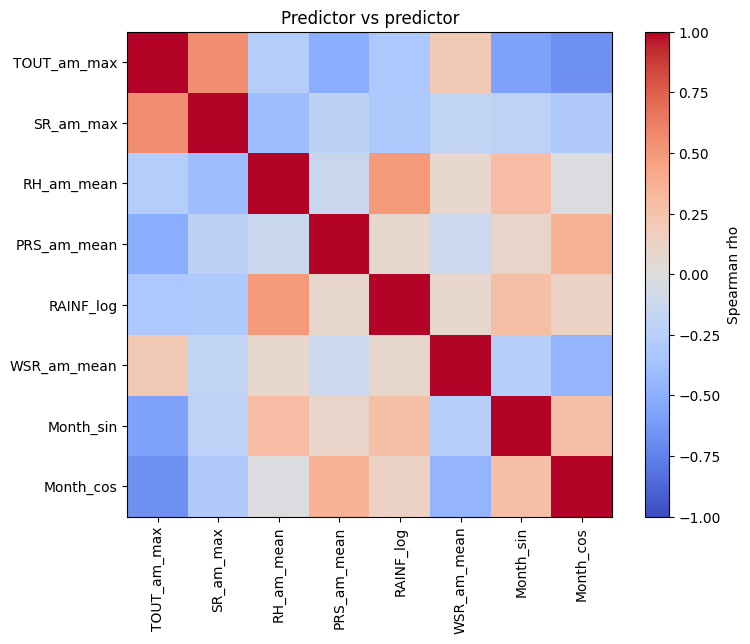

Threshold |rho| >= 0.15
Keep : ['TOUT_am_max', 'SR_am_max', 'RH_am_mean', 'PRS_am_mean', 'RAINF_log', 'WSR_am_mean', 'Month_sin', 'Month_cos']
Drop candidates: []


In [21]:
# Analyzing correlation between Predictors and targets through spearman again.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

targets    = ["O3_max_next", "PM25_max_next"]
predictors = final_features   #[c for c in PCA_cols if c not in targets]

pdf = ordered.toPandas()
pdf["date"] = pd.to_datetime(pdf["DateParsed"])
pdf = pdf.sort_values("date").reset_index(drop=True)
n = len(pdf)

def spearman_table(data, predictors, targets):
    rows = []
    for p in predictors:
        row = {"variable": p}
        for t in targets:
            rho, pval = spearmanr(data[p], data[t], nan_policy="omit")
            row[f"rho_{t}"], row[f"p_{t}"] = rho, pval
        rows.append(row)
    return pd.DataFrame(rows).set_index("variable")

def summarize(tbl, targets):
    out = pd.DataFrame(index=tbl.index)
    for t in targets:
        out[f"rho_{t}"] = tbl[f"rho_{t}"].round(2)
        out[f"sig_{t}"] = np.where(tbl[f"p_{t}"] < 0.05, "*", "")
    out["max_abs_rho"] = tbl[[f"rho_{t}" for t in targets]].abs().max(axis=1).round(2)
    return out.sort_values("max_abs_rho", ascending=False)

# 1) Same-day relationship
tbl_same = spearman_table(pdf, predictors, targets)
print("Predictors vs targets, same day (* = p < 0.05)")
display(summarize(tbl_same, targets))

# 2) Next-day relationship (what a forecast actually needs)
#consecutive = (pdf["date"].shift(-1) - pdf["date"]).dt.days == 1
#for t in targets:
#    pdf[f"{t}_next"] = pdf[t].shift(-1).where(consecutive)
#targets_next = [f"{t}_next" for t in targets]
#print("Consecutive-day pairs available:", int(consecutive.sum()))
#tbl_next = spearman_table(pdf, predictors, targets_next)
#print("Predictors today vs targets tomorrow (* = p < 0.05)")
#display(summarize(tbl_next, targets_next))

# 3) Redundancy among predictors
corr_pred = pdf[predictors].corr(method="spearman")
pairs = (corr_pred.where(np.triu(np.ones(corr_pred.shape, dtype=bool), k=1))
         .stack().reset_index())
pairs.columns = ["var1", "var2", "rho"]
print("Highly correlated predictor pairs (|rho| >= 0.8)")
display(pairs[pairs["rho"].abs() >= 0.8].sort_values("rho", key=abs, ascending=False))

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr_pred, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(predictors))); ax.set_xticklabels(predictors, rotation=90)
ax.set_yticks(range(len(predictors))); ax.set_yticklabels(predictors)
plt.colorbar(im, label="Spearman rho"); plt.title("Predictor vs predictor"); plt.tight_layout(); plt.show()

# 4) Automatic drop candidates (sin/cos pairs are judged together)
groups = {"Month": ["Month_sin", "Month_cos"], "WDV": ["WDV_sin", "WDV_cos"]}
group_of = {v: g for g, vs in groups.items() for v in vs}
unit = pd.Series({v: group_of.get(v, v) for v in predictors})

THRESH = 1.96 / np.sqrt(n - 1)     # ~0.19 for n = 108 (approx. |rho| needed for p < 0.05)
rho_cols = [f"rho_{t}" for t in targets]
strength = tbl_same[rho_cols].abs().max(axis=1).groupby(unit).max()

keep = [v for v in predictors if strength[unit[v]] >= THRESH]
drop = [v for v in predictors if v not in keep]
print(f"Threshold |rho| >= {THRESH:.2f}")
print("Keep :", keep)
print("Drop candidates:", drop)



*   O3: the morning variables keep the same signs and ranking as the full-day ones, with lower values: TOUT +0.51 vs +0.59, SR +0.50 vs +0.52, RH −0.43 vs −0.61. That drop is the expected cost of seeing only the morning, and the correlations are clearly above what the next-day table gave (TOUT +0.39, RH −0.46 in absolute terms, so RH is similar and TOUT/SR are better). So same-day morning prediction should be somewhat more informative than next-day.

*  PM25: still weak. The largest value is Month_sin at +0.28 and WSR at −0.27, which is about the same as before. With rho² of roughly 0.08, expect the same negative result.

*  Redundancy: the “highly correlated pairs” table is empty, so no pair reaches 0.8. TOUT_am_max and SR_am_max correlate at about 0.5 (heatmap), which is much lower than the 0.84 of the full-day versions, because the morning temperature and radiation haven’t peaked yet.

*  Everything passes the threshold, so none of the eight features needs dropping. WSR_am_mean is kept for PM25 only.



In [25]:
import numpy as np
import pandas as pd
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import RegressionEvaluator, BinaryClassificationEvaluator
from pyspark.sql import functions as F

feature_sets = {
    "with_month": final_features,
    "no_month":   [c for c in final_features if not c.startswith("Month_")],
}

def prep_stages(cols):
    # The scaler is part of the Pipeline, so fit() on train learns the mean/std from train only
    return [VectorAssembler(inputCols=cols, outputCol="raw_features"),
            StandardScaler(inputCol="raw_features", outputCol="features",
                           withMean=True, withStd=True)]

# ------------------------------------------------------------------
# A) O3: regression, then apply the thresholds to the prediction
# ------------------------------------------------------------------
def o3_class(c):
    c = F.round(c)
    return (F.when(c <= O3_GOOD_MAX, "good")
             .when(c <= O3_REG_MAX, "regular")
             .otherwise("contingency"))

def eval_o3(pred, label="O3_max_next"):
    ev = lambda m: RegressionEvaluator(labelCol=label, predictionCol="prediction",
                                       metricName=m).evaluate(pred)
    p = pred.withColumn("pred_class", o3_class(F.col("prediction")))
    n = p.count()
    acc = p.filter(F.col("pred_class") == F.col("O3_class_next")).count() / n
    def recall(cls):
        d = p.filter(F.col("O3_class_next") == cls)
        k = d.count()
        return d.filter(F.col("pred_class") == cls).count() / k if k else np.nan
    bias = pred.agg(F.avg(F.col("prediction") - F.col(label))).first()[0]
    return {"RMSE": ev("rmse"), "MAE": ev("mae"), "R2": ev("r2"), "bias": bias,
            "class_acc": acc, "recall_good": recall("good"), "recall_regular": recall("regular")}

def lr(reg, en):
    return LinearRegression(featuresCol="features", labelCol="O3_max_next",
                            regParam=reg, elasticNetParam=en)
def rf(depth):
    return RandomForestRegressor(featuresCol="features", labelCol="O3_max_next",
                                 numTrees=200, maxDepth=depth,
                                 minInstancesPerNode=5, seed=42)

grids = {
    "LinearReg":  [(f"reg={r},en={e}", (lambda r=r, e=e: lr(r, e)))
                   for r in [0.01, 0.1, 1.0] for e in [0.0, 0.5, 1.0]],
    "RandForest": [(f"depth={d}", (lambda d=d: rf(d))) for d in [2, 3, 5]],
}

rmse_ev = RegressionEvaluator(labelCol="O3_max_next", predictionCol="prediction",
                              metricName="rmse")

def expanding_cv(make_model, cols, data, n_folds=4, min_train_frac=0.5):
    """Train on the earliest block, validate on the block right after it, then expand."""
    n = data.count()
    start = int(n * min_train_frac)
    step = (n - start) // n_folds
    scores = []
    for k in range(n_folds):
        tr_end = start + k * step
        va_end = tr_end + step
        tr = data.filter(F.col("row_id") <= tr_end)
        va = data.filter((F.col("row_id") > tr_end) & (F.col("row_id") <= va_end))
        m = Pipeline(stages=prep_stages(cols) + [make_model()]).fit(tr)
        scores.append(rmse_ev.evaluate(m.transform(va)))
    return float(np.mean(scores))

rows = []

# Baseline: constant = median of the training O3 (time/weather-only requirement)
med = float(train_df.approxQuantile("O3_max_next", [0.5], 0.01)[0])
base = test_df.withColumn("prediction", F.lit(med))
rows.append({"features": "-", "model": "Baseline (train median)", "params": f"{med}",
             "cv_rmse": np.nan, **eval_o3(base)})

for fs_name, cols in feature_sets.items():
    for fam, options in grids.items():
        scored = [(expanding_cv(mk, cols, train_df), pname, mk) for pname, mk in options]
        cv_rmse, best_name, best_mk = min(scored, key=lambda t: t[0])
        final = Pipeline(stages=prep_stages(cols) + [best_mk()]).fit(train_df)
        rows.append({"features": fs_name, "model": fam, "params": best_name,
                     "cv_rmse": cv_rmse, **eval_o3(final.transform(test_df))})

res_o3 = pd.DataFrame(rows).round(3)
display(res_o3)

# ------------------------------------------------------------------
# B) PM25: binary classification (1 = contingency, 0 = regular)
# ------------------------------------------------------------------
n_tr = train_df.count()
n_pos = train_df.filter(F.col("PM25_label_bin") == 1).count()
n_neg = n_tr - n_pos
w_pos, w_neg = n_tr / (2 * n_pos), n_tr / (2 * n_neg)     # balanced class weights
train_w = train_df.withColumn(
    "w", F.when(F.col("PM25_label_bin") == 1, w_pos).otherwise(w_neg))

def eval_pm25(pred):
    L, P = F.col("PM25_label_bin"), F.col("prediction")
    tp = pred.filter((L == 1) & (P == 1)).count()
    fn = pred.filter((L == 1) & (P == 0)).count()
    tn = pred.filter((L == 0) & (P == 0)).count()
    fp = pred.filter((L == 0) & (P == 1)).count()
    rec_c = tp / (tp + fn) if tp + fn else np.nan     # contingency days caught
    rec_r = tn / (tn + fp) if tn + fp else np.nan     # regular days correctly recognized
    auc = (BinaryClassificationEvaluator(labelCol="PM25_label_bin",
           rawPredictionCol="rawPrediction", metricName="areaUnderROC").evaluate(pred)
           if "rawPrediction" in pred.columns else np.nan)
    return {"accuracy": (tp + tn) / (tp + tn + fp + fn), "recall_contingency": rec_c,
            "recall_regular": rec_r, "balanced_acc": np.nanmean([rec_c, rec_r]),
            "AUC": auc, "TP": tp, "FN": fn, "TN": tn, "FP": fp}

rows = []
base = test_df.withColumn("prediction", F.lit(1.0))          # always "contingency"
rows.append({"features": "-", "model": "Baseline (always contingency)", **eval_pm25(base)})

clfs = {
    "LogReg":     lambda: LogisticRegression(featuresCol="features", labelCol="PM25_label_bin",
                                             weightCol="w", regParam=0.1, elasticNetParam=0.0),
    "RandForest": lambda: RandomForestClassifier(featuresCol="features", labelCol="PM25_label_bin",
                                                 weightCol="w", numTrees=200, maxDepth=3,
                                                 minInstancesPerNode=5, seed=42),
}
for fs_name, cols in feature_sets.items():
    for cname, mk in clfs.items():
        m = Pipeline(stages=prep_stages(cols) + [mk()]).fit(train_w)
        rows.append({"features": fs_name, "model": cname, **eval_pm25(m.transform(test_df))})

res_pm = pd.DataFrame(rows).round(3)
display(res_pm)

,features,model,params,cv_rmse,RMSE,MAE,R2,bias,class_acc,recall_good,recall_regular
0,-,Baseline (train median),44.0,NaN,22.038,18.139,-1.029,-15.694,0.361,1.000,0.000
1,with_month,LinearReg,"reg=1.0,en=1.0",14.130,16.790,12.767,-0.178,-8.633,0.667,0.923,0.522
2,with_month,RandForest,depth=3,13.339,15.794,11.914,-0.042,-6.704,0.694,0.846,0.609
3,no_month,LinearReg,"reg=1.0,en=1.0",14.796,14.438,10.807,0.129,-3.332,0.750,0.538,0.870
4,no_month,RandForest,depth=3,13.533,15.256,11.354,0.028,-5.691,0.750,0.769,0.739


,features,model,accuracy,recall_contingency,recall_regular,balanced_acc,AUC,TP,FN,TN,FP
0,-,Baseline (always contingency),0.861,1.000,0.0,0.500,NaN,31,0,0,5
1,with_month,LogReg,0.139,0.000,1.0,0.500,0.335,0,31,5,0
2,with_month,RandForest,0.417,0.387,0.6,0.494,0.523,12,19,3,2
3,no_month,LogReg,0.528,0.581,0.2,0.390,0.406,18,13,1,4
4,no_month,RandForest,0.556,0.548,0.6,0.574,0.458,17,14,3,2


In [26]:
#  Including also XGBoost algorithm.

from pyspark.ml.regression import GBTRegressor
from pyspark.ml.classification import GBTClassifier

try:
    from xgboost.spark import SparkXGBRegressor, SparkXGBClassifier
    HAS_XGB = True
except Exception as e:
    HAS_XGB = False
    print("xgboost.spark not available, running GBT only:", repr(e)[:200])

# Reuses from earlier cells: feature_sets, prep_stages, expanding_cv, eval_o3, eval_pm25,
# train_df, test_df, train_w, res_o3, res_pm

# ------------------------------------------------------------------
# A) O3 regression: same expanding-window CV as the other models
# ------------------------------------------------------------------
def xgb_reg(d, n):
    return SparkXGBRegressor(features_col="features", label_col="O3_max_next",
                             num_workers=1, n_estimators=n, learning_rate=0.05,
                             max_depth=d, min_child_weight=5, subsample=0.8,
                             colsample_bytree=0.8, reg_lambda=5.0, random_state=42)

def gbt_reg(d, n):
    return GBTRegressor(featuresCol="features", labelCol="O3_max_next",
                        maxIter=n, maxDepth=d, stepSize=0.05, subsamplingRate=0.8,
                        minInstancesPerNode=5, seed=42)

o3_families = {}
if HAS_XGB:
    o3_families["XGBoost (Spark)"] = [(f"depth={d},n={n}", (lambda d=d, n=n: xgb_reg(d, n)))
                                      for d in [1, 2, 3] for n in [100, 300]]
o3_families["GBT (Spark)"] = [(f"depth={d},iter={n}", (lambda d=d, n=n: gbt_reg(d, n)))
                              for d in [1, 2, 3] for n in [50, 150]]

rows_o3 = []
for fs_name, cols in feature_sets.items():
    for fam, options in o3_families.items():
        scored = [(expanding_cv(mk, cols, train_df), pname, mk) for pname, mk in options]
        cv_rmse, best_name, best_mk = min(scored, key=lambda t: t[0])
        final = Pipeline(stages=prep_stages(cols) + [best_mk()]).fit(train_df)
        rows_o3.append({"features": fs_name, "model": fam, "params": best_name,
                        "cv_rmse": cv_rmse, **eval_o3(final.transform(test_df))})

# ------------------------------------------------------------------
# B) PM25 classification (1 = contingency), same balanced weights ("w") as before
# ------------------------------------------------------------------
pm_clfs = {}
if HAS_XGB:
    pm_clfs["XGBoost (Spark)"] = lambda: SparkXGBClassifier(
        features_col="features", label_col="PM25_label_bin", weight_col="w",
        num_workers=1, n_estimators=200, learning_rate=0.05, max_depth=2,
        min_child_weight=1, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=5.0, random_state=42)
pm_clfs["GBT (Spark)"] = lambda: GBTClassifier(
    featuresCol="features", labelCol="PM25_label_bin", weightCol="w",
    maxIter=100, maxDepth=2, stepSize=0.05, subsamplingRate=0.8,
    minInstancesPerNode=3, seed=42)

rows_pm = []
for fs_name, cols in feature_sets.items():
    for cname, mk in pm_clfs.items():
        m = Pipeline(stages=prep_stages(cols) + [mk()]).fit(train_w)
        rows_pm.append({"features": fs_name, "model": cname, **eval_pm25(m.transform(test_df))})

# ------------------------------------------------------------------
# C) Side-by-side comparison with the models you already have
# ------------------------------------------------------------------
res_o3_all = pd.concat([res_o3, pd.DataFrame(rows_o3).round(3)], ignore_index=True)
res_pm_all = pd.concat([res_pm, pd.DataFrame(rows_pm).round(3)], ignore_index=True)

print("O3 (sorted by test RMSE)")
display(res_o3_all.sort_values("RMSE"))
print("PM25 (sorted by balanced accuracy)")
display(res_pm_all.sort_values("balanced_acc", ascending=False))

INFO:XGBoost-PySpark:Running xgboost-3.4.1 on 1 workers with
	booster params: {'objective': 'reg:squarederror', 'colsample_bytree': 0.8, 'device': 'cpu', 'learning_rate': 0.05, 'max_depth': 1, 'min_child_weight': 5, 'random_state': 42, 'reg_lambda': 5.0, 'subsample': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': nan}
INFO:XGBoost-PySpark:Finished xgboost training!
INFO:XGBoost-PySpark:Running xgboost-3.4.1 on 1 workers with
	booster params: {'objective': 'reg:squarederror', 'colsample_bytree': 0.8, 'device': 'cpu', 'learning_rate': 0.05, 'max_depth': 1, 'min_child_weight': 5, 'random_state': 42, 'reg_lambda': 5.0, 'subsample': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': nan}
INFO:XGBoost-PySpark:Finished xgboost training!
INFO:XGBoost-PySpark:Running xgboost-3.4.1 on 1 workers with
	booster params: {'object

O3 (sorted by test RMSE)


,features,model,params,cv_rmse,RMSE,MAE,R2,bias,class_acc,recall_good,recall_regular
3,no_month,LinearReg,"reg=1.0,en=1.0",14.796,14.438,10.807,0.129,-3.332,0.750,0.538,0.870
7,no_month,XGBoost (Spark),"depth=2,n=100",13.562,15.014,11.185,0.058,-4.246,0.694,0.538,0.783
5,with_month,XGBoost (Spark),"depth=1,n=100",13.661,15.029,11.147,0.056,-5.664,0.778,0.769,0.783
4,no_month,RandForest,depth=3,13.533,15.256,11.354,0.028,-5.691,0.750,0.769,0.739
8,no_month,GBT (Spark),"depth=1,iter=150",14.585,15.453,11.464,0.002,-5.264,0.639,0.615,0.652
2,with_month,RandForest,depth=3,13.339,15.794,11.914,-0.042,-6.704,0.694,0.846,0.609
1,with_month,LinearReg,"reg=1.0,en=1.0",14.130,16.790,12.767,-0.178,-8.633,0.667,0.923,0.522
6,with_month,GBT (Spark),"depth=2,iter=50",14.812,17.593,13.325,-0.293,-6.267,0.556,0.538,0.565
0,-,Baseline (train median),44.0,NaN,22.038,18.139,-1.029,-15.694,0.361,1.000,0.000


PM25 (sorted by balanced accuracy)


,features,model,accuracy,recall_contingency,recall_regular,balanced_acc,AUC,TP,FN,TN,FP
4,no_month,RandForest,0.556,0.548,0.6,0.574,0.458,17,14,3,2
7,no_month,XGBoost (Spark),0.556,0.548,0.6,0.574,0.535,17,14,3,2
5,with_month,XGBoost (Spark),0.528,0.516,0.6,0.558,0.561,16,15,3,2
6,with_month,GBT (Spark),0.500,0.484,0.6,0.542,0.523,15,16,3,2
0,-,Baseline (always contingency),0.861,1.000,0.0,0.500,NaN,31,0,0,5
1,with_month,LogReg,0.139,0.000,1.0,0.500,0.335,0,31,5,0
2,with_month,RandForest,0.417,0.387,0.6,0.494,0.523,12,19,3,2
8,no_month,GBT (Spark),0.556,0.581,0.4,0.490,0.600,18,13,2,3
3,no_month,LogReg,0.528,0.581,0.2,0.390,0.406,18,13,1,4


### These are the results from moving the cutoff hour to 11 am:

*  The best RMSE is essentially the same (14.44 vs 14.50). The later cutoff gave no measurable gain. The extra two hours don’t add information.

*  The model ranking flipped again. With cutoff 9, boosted models led and LinearReg was at R² 0.05. Now LinearReg leads with 0.13 and the boosted models drop to 0.00-0.06. When the ranking changes with a small tweak, the differences between models are noise, not a signal.

*  LinearReg no_month is the most useful in this table. It has the best RMSE, the highest recall_regular (0.87), and a small bias (−3.3). XGBoost has recall_regular 0.78 and a worse RMSE.

*  Month features hurt LinearReg again (R² −0.18 vs +0.13). That is the extrapolation problem from before, and it is now consistent across the three runs.

*  cv_rmse (13.3-14.8) is lower than the test RMSE (14.4-15.8) for most models, which is a mild sign of the test period being harder than the training period (August onward).

**Regarding PM25**

No change in the conclusion. No model is a reliable improvement over the baseline.

*  The best balanced accuracy is 0.574 (RandForest and XGBoost, no_month), with AUC of 0.46 and 0.54.

*  The baseline accuracy (0.861) is higher than every model’s (0.14-0.56).
*  LogReg with_month predicts “regular” for every day again